# 02 — Explore the data

Before building any model we look at the data. We want to know what the target looks like, which specs move with price, which specs move with *each other*, and how prices differ across brands and chips. Every plot is saved to `results/` and is followed by a one-sentence takeaway.

**Robustness check.** The clean data has 702 phones. 695 have storage parsed from the model name (`storage_source = "name"`), and 7 Infinix phones had storage and price filled in by a manual web lookup (`"web_lookup"`). Where it matters we show results for both sets. In the scatter plots the 7 looked-up phones are drawn in orange.

Note: this is exploration on the **whole** dataset (no train/test split yet). We only look; we fit no models and choose nothing from the test set. The split is made in Phase 3.

### Setup
**matplotlib** draws the figures. We use one blue for single-series plots and orange only to mark the web-lookup phones, and we keep grid lines light so the data stands out.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from features import NUMERIC_FEATURES

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
})

df = pd.read_csv("../data/processed/phones_clean.csv")
name_only = df[df["storage_source"] == "name"]
print("All phones:", len(df), "| name-only:", len(name_only), "| web-lookup:", (df["storage_source"] == "web_lookup").sum())

All phones: 702 | name-only: 695 | web-lookup: 7


## 1. Distribution of price and of log price
A **histogram** splits the values into bins and shows how many phones fall in each. We expect price to be **right-skewed** (a long tail of expensive phones) and log price to be roughly symmetric.

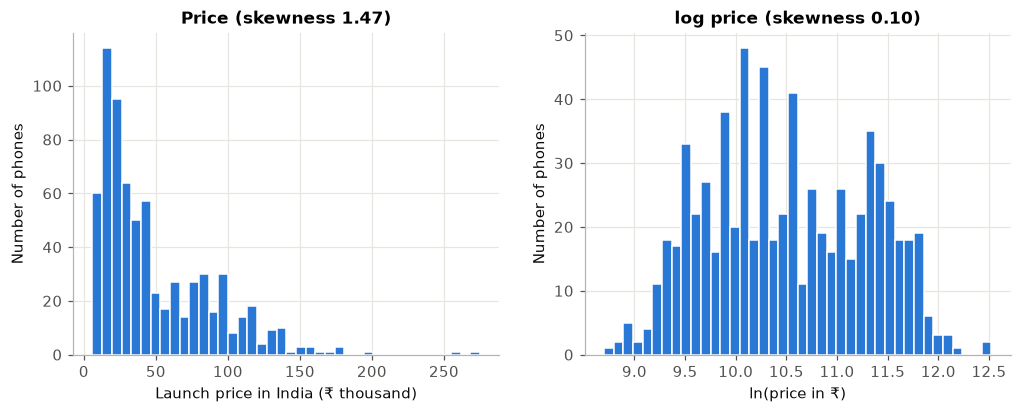

count       702.0
mean      49166.0
std       39238.0
min        5999.0
25%       19990.0
50%       34999.0
75%       74900.0
max      274999.0


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["price_inr"] / 1000, bins=40, color=BLUE, edgecolor="white", linewidth=1)
axes[0].set(title=f"Price (skewness {df['price_inr'].skew():.2f})", xlabel="Launch price in India (₹ thousand)", ylabel="Number of phones")
axes[1].hist(df["log_price"], bins=40, color=BLUE, edgecolor="white", linewidth=1)
axes[1].set(title=f"log price (skewness {df['log_price'].skew():.2f})", xlabel="ln(price in ₹)", ylabel="Number of phones")
fig.savefig("../results/fig02_price_hist.png")
plt.show()
print(df["price_inr"].describe().round(0).to_string())

**Takeaway:** price is strongly right-skewed (skewness 1.47, median ₹35k but a tail up to ₹2.75 lakh), while log price is almost symmetric (skewness 0.10). This supports modelling log price.

## 2. Log price against each numeric spec
For each spec we draw a **scatter plot** (one dot per phone) against log price. The title gives the **Pearson correlation** *r*, a number from −1 to +1 that measures how close the points are to a straight line: +1 means a perfect rising line, 0 means no linear relationship, and −1 a perfect falling line. *r* only captures *linear*, *one-variable-at-a-time* association. It says nothing about cause, and it can be distorted by a third variable (we will see an example with battery).

RAM and storage come in doublings (4, 8, 16 GB …), so we plot `log2_ram` and `log2_storage`, where +1 means "double". Small random horizontal **jitter** is added to the discrete specs only for drawing, so that dots stacked on the same value become visible. It is not used in any calculation.

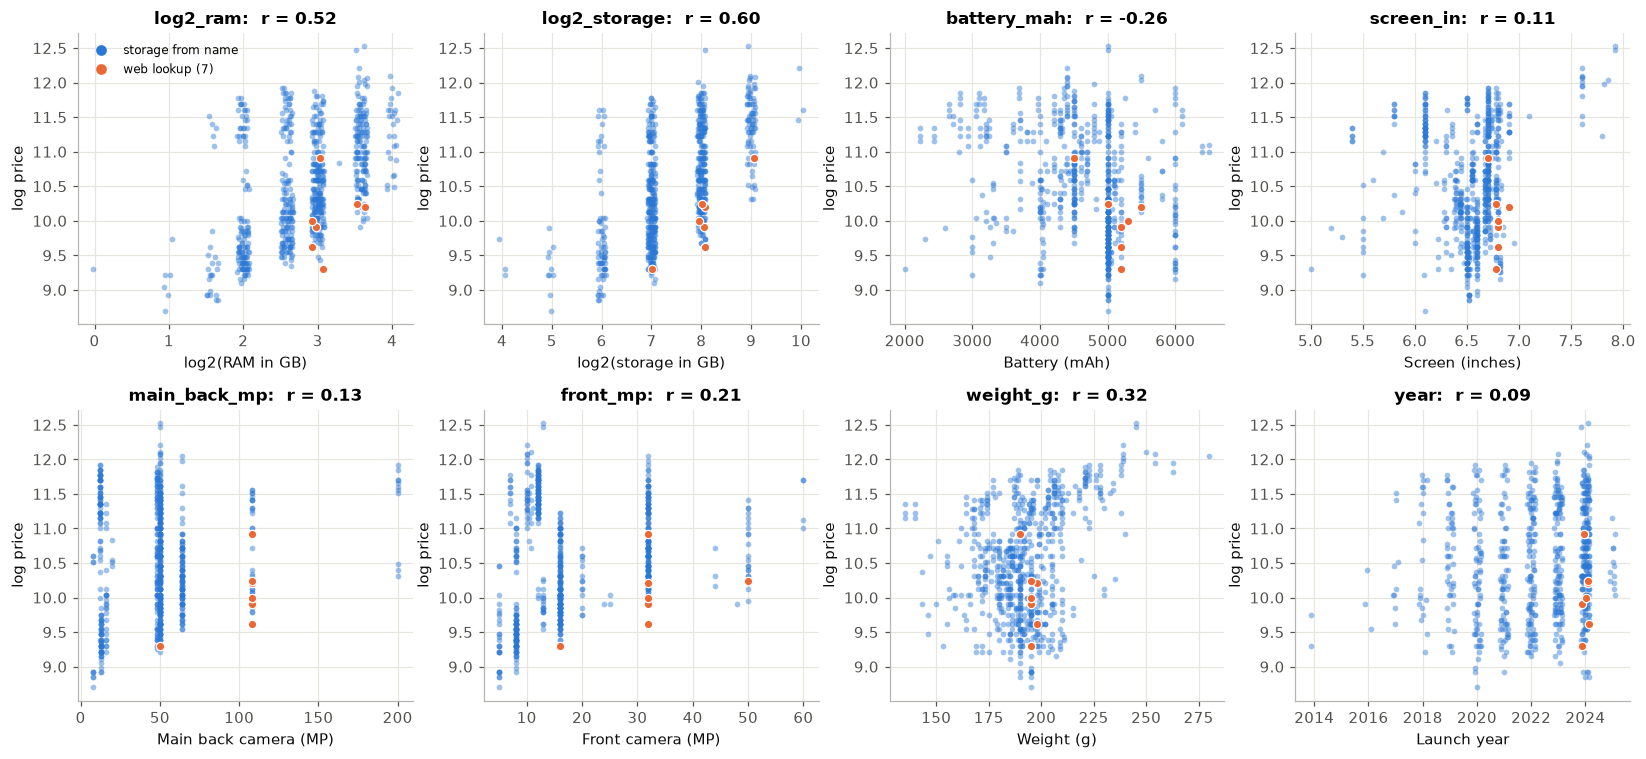

In [3]:
plot_specs = [("log2_ram", "log2(RAM in GB)"), ("log2_storage", "log2(storage in GB)"),
              ("battery_mah", "Battery (mAh)"), ("screen_in", "Screen (inches)"),
              ("main_back_mp", "Main back camera (MP)"), ("front_mp", "Front camera (MP)"),
              ("weight_g", "Weight (g)"), ("year", "Launch year")]
discrete = {"log2_ram": 0.08, "log2_storage": 0.08, "year": 0.15}
rng = np.random.default_rng(42)
is_web = df["storage_source"] == "web_lookup"

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (col, label) in zip(axes.ravel(), plot_specs):
    x = df[col] + (rng.uniform(-1, 1, len(df)) * discrete[col] if col in discrete else 0)
    ax.scatter(x[~is_web], df.loc[~is_web, "log_price"], s=14, color=BLUE, alpha=0.45, linewidths=0)
    ax.scatter(x[is_web], df.loc[is_web, "log_price"], s=30, color=ORANGE, edgecolor="white", linewidths=0.8)
    r = df[col].corr(df["log_price"])
    ax.set(title=f"{col}:  r = {r:.2f}", xlabel=label, ylabel="log price")
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=BLUE, label="storage from name"),
                           plt.Line2D([], [], marker="o", ls="", color=ORANGE, label="web lookup (7)")],
                  loc="upper left", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("../results/fig02_scatter_specs.png")
plt.show()

The table below gives the same correlations for both versions of the data, plus `n_back_cameras` (not plotted).

In [4]:
corr_table = pd.DataFrame({
    "r (name-only, n=695)": name_only[NUMERIC_FEATURES].corrwith(name_only["log_price"]),
    "r (with web lookup, n=702)": df[NUMERIC_FEATURES].corrwith(df["log_price"]),
}).sort_values("r (with web lookup, n=702)", ascending=False).round(3)
corr_table["difference"] = (corr_table.iloc[:, 1] - corr_table.iloc[:, 0]).round(3)
corr_table.to_csv("../results/correlations_with_log_price.csv")
corr_table

,"r (name-only, n=695)","r (with web lookup, n=702)",difference
log2_storage,0.609,0.604,-0.005
log2_ram,0.529,0.523,-0.006
weight_g,0.318,0.316,-0.002
n_back_cameras,0.255,0.258,0.003
front_mp,0.216,0.208,-0.008
main_back_mp,0.140,0.129,-0.011
screen_in,0.119,0.113,-0.006
year,0.094,0.088,-0.006
battery_mah,-0.258,-0.261,-0.003


**Takeaway:** storage (*r* = 0.60) and RAM (*r* = 0.52) are clearly the specs most related to price, as expected. Weight comes next (0.32), and camera megapixels (0.13 main, 0.21 front), screen size (0.11) and launch year (0.09) are only weakly related. Adding the 7 looked-up phones changes no correlation by more than 0.011.

One expectation **failed**: battery is not near zero but *negative* (*r* = −0.26). We check why below.

### Why is battery negatively correlated with price? A third variable
Apple sells expensive phones with small batteries. If one brand is both "small battery" and "high price", it creates a negative correlation across the whole dataset even if battery itself has no effect. This is called **confounding**: a third variable (here brand) influences both things we are comparing. We redraw the battery plot with Apple highlighted and recompute *r* without Apple.

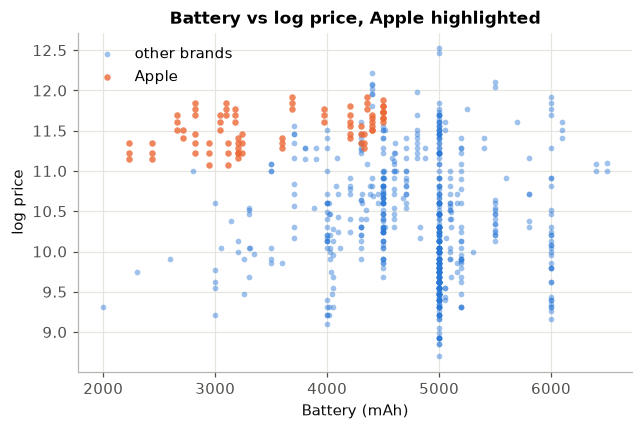

r(battery, log price), all phones:     -0.261
r(battery, log price), without Apple:  -0.041
r(year, log price),    all phones:     0.088
r(year, log price),    without Apple:  0.224

Median battery and price, Apple vs others:
        battery_mah  price_inr
Apple        3240.0   102499.0
others       5000.0    29999.0


In [5]:
is_apple = df["brand"] == "Apple"
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(df.loc[~is_apple, "battery_mah"], df.loc[~is_apple, "log_price"], s=14, color=BLUE, alpha=0.45, linewidths=0, label="other brands")
ax.scatter(df.loc[is_apple, "battery_mah"], df.loc[is_apple, "log_price"], s=18, color=ORANGE, alpha=0.8, linewidths=0, label="Apple")
ax.set(title="Battery vs log price, Apple highlighted", xlabel="Battery (mAh)", ylabel="log price")
ax.legend(frameon=False)
fig.savefig("../results/fig02_battery_apple.png")
plt.show()

no_apple = df[~is_apple]
print(f"r(battery, log price), all phones:     {df['battery_mah'].corr(df['log_price']):.3f}")
print(f"r(battery, log price), without Apple:  {no_apple['battery_mah'].corr(no_apple['log_price']):.3f}")
print(f"r(year, log price),    all phones:     {df['year'].corr(df['log_price']):.3f}")
print(f"r(year, log price),    without Apple:  {no_apple['year'].corr(no_apple['log_price']):.3f}")
print("\nMedian battery and price, Apple vs others:")
print(df.groupby(np.where(is_apple, "Apple", "others"))[["battery_mah", "price_inr"]].median())

**Takeaway:** without Apple the battery correlation drops from −0.26 to −0.04, essentially zero, which matches the expected finding. The negative value came from Apple (median 3,240 mAh at ₹1.02 lakh vs 5,000 mAh at ₹30k for other brands), not from batteries making phones cheaper.

The same effect hides part of the year trend (*r* rises from 0.09 to 0.22 without Apple). This is exactly why the models later include brand alongside the specs: a regression coefficient measures a spec's effect **holding brand fixed**, which a one-variable correlation cannot do.

## 3. How the specs relate to each other
A **correlation heatmap** shows *r* for every pair of numeric features. Red means positive, blue negative, and grey near zero. Features that are strongly correlated with each other carry overlapping information. In a linear model this is called **multicollinearity**, and it makes the individual coefficients unstable (we measure it properly in Phase 4).

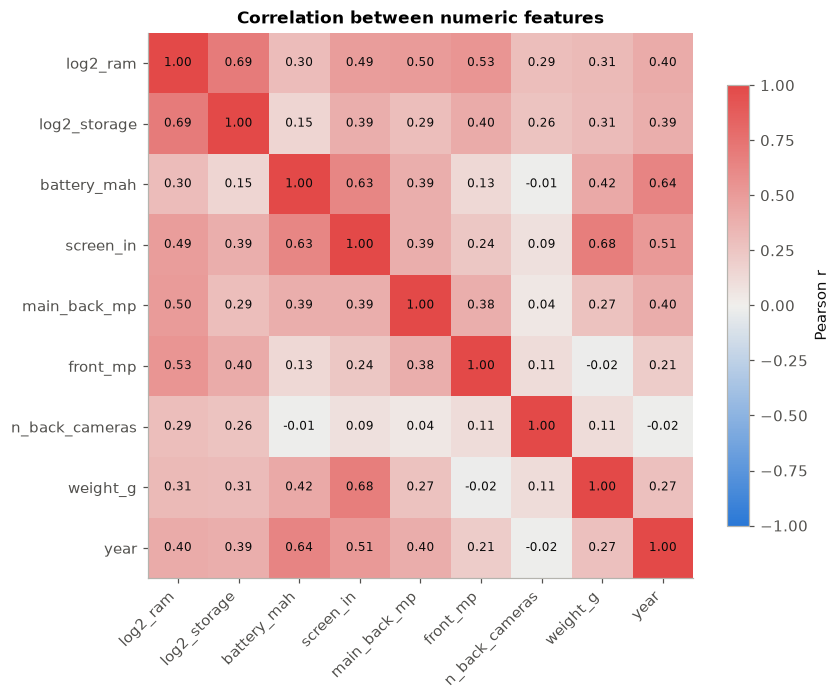

Most correlated feature pairs:
 log2_ram     log2_storage    0.69
screen_in    weight_g        0.68
battery_mah  year            0.64
             screen_in       0.63
log2_ram     front_mp        0.53
screen_in    year            0.51


In [6]:
corr = df[NUMERIC_FEATURES].corr()
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
fig.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
ax.set_title("Correlation between numeric features")
fig.savefig("../results/fig02_corr_heatmap.png")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print("Most correlated feature pairs:\n", pairs.head(6).round(2).to_string())

**Takeaway:** RAM and storage are strongly correlated (*r* = 0.69), because phones with more RAM usually also come with more storage. A linear model will therefore struggle to separate "the value of RAM" from "the value of storage", and their individual coefficients will be uncertain even if their combined effect is clear. Battery and year (0.64) and screen and weight (0.68) are also strongly linked.

## 4. Log price by brand and by chip family
A **box plot** summarises a group. The line inside the box is the **median** (the middle phone), the box spans the middle 50 % of phones (the **interquartile range**, IQR), the whiskers reach the furthest phones within 1.5 × IQR, and dots beyond them are outliers. Groups are sorted by median, and the number of phones *n* is shown in each label because small groups are less reliable.

/tmp/ipykernel_20512/443074379.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(groups, vert=False, widths=0.6, patch_artist=True,
/tmp/ipykernel_20512/443074379.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(groups, vert=False, widths=0.6, patch_artist=True,


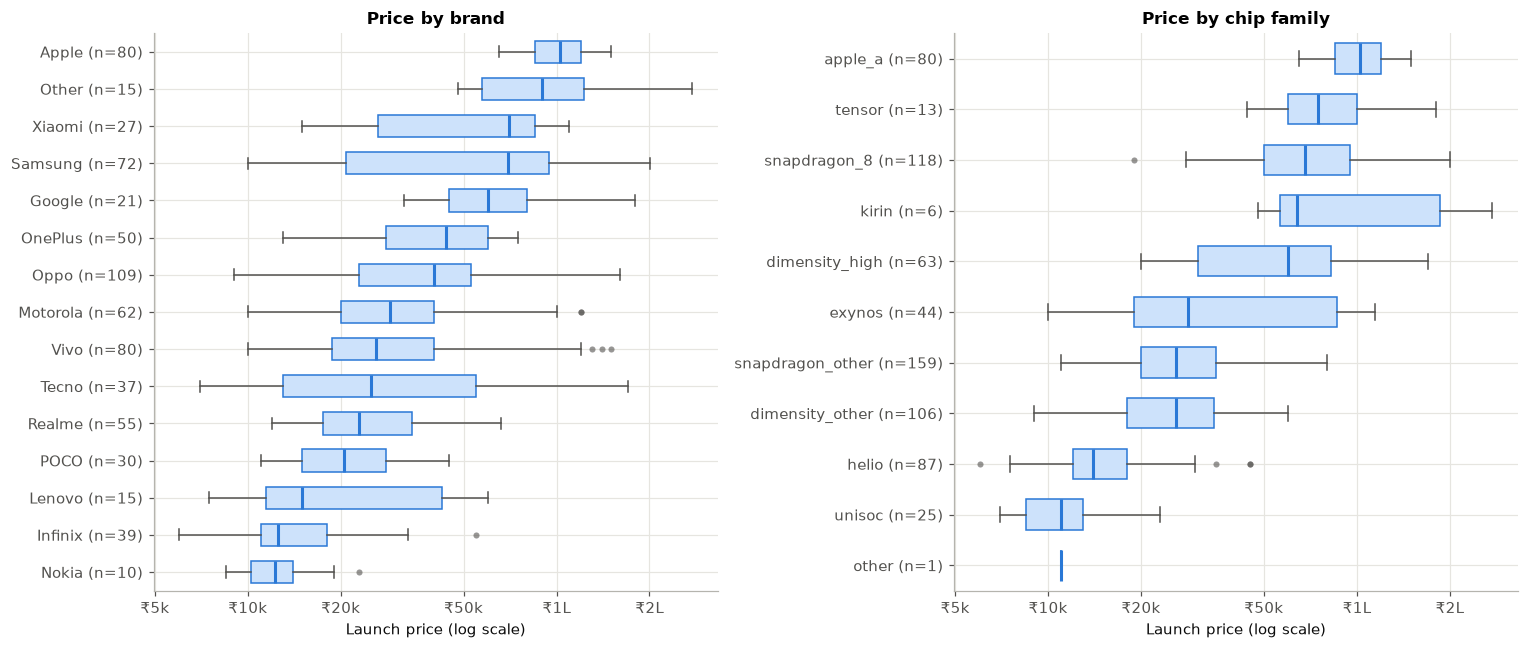

brand
Nokia        12249.0
Infinix      12499.0
Lenovo       14999.0
POCO         20499.0
Realme       22999.0
Tecno        24999.0
Vivo         25999.0
Motorola     28999.0
Oppo         39999.0
OnePlus      43999.0
Google       59999.0
Samsung      69900.0
Xiaomi       69999.0
Other        89999.0
Apple       102499.0


In [7]:
def sorted_boxplot(ax, data, group, title):
    order = data.groupby(group)["log_price"].median().sort_values().index
    groups = [data.loc[data[group] == g, "log_price"] for g in order]
    ax.boxplot(groups, vert=False, widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
               whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
               flierprops=dict(marker="o", markersize=4, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.6))
    ax.set_yticks(range(1, len(order) + 1), [f"{g} (n={len(x)})" for g, x in zip(order, groups)])
    # second axis label in rupees, for readability (same scale, just relabelled)
    ticks = np.log([5e3, 1e4, 2e4, 5e4, 1e5, 2e5])
    ax.set_xticks(ticks, ["₹5k", "₹10k", "₹20k", "₹50k", "₹1L", "₹2L"])
    ax.set(title=title, xlabel="Launch price (log scale)")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sorted_boxplot(axes[0], df, "brand", "Price by brand")
sorted_boxplot(axes[1], df, "chip_family", "Price by chip family")
fig.tight_layout()
fig.savefig("../results/fig02_box_brand_chip.png")
plt.show()

print(df.groupby("brand")["price_inr"].median().sort_values().round(0).to_string())

**Takeaway (brand):** median prices run from about ₹12k (Nokia, Infinix) to ₹1.02 lakh (Apple). Apple, "Other" (mostly Sony and Huawei flagships), Xiaomi, Samsung and Google sit at the top, and budget brands (Infinix, Nokia, Lenovo, POCO) at the bottom. These raw gaps mix two things, *better specs* and a *brand premium*. Separating the two is the point of Phases 4–8.

**Takeaway (chip):** chip family sorts phones into clear price tiers. Unisoc and Helio are budget (~₹11–14k), Snapdragon-other, Dimensity-other and Exynos are mid-range (~₹26–28k), and Dimensity-high, Snapdragon 8, Tensor and Apple A are flagships (₹60k+). The `other` (1 phone) and `kirin` (6 phones) groups are too small to trust.

## 5. How many phones per brand and per year
Small groups give noisy estimates, so we check how the data is spread.

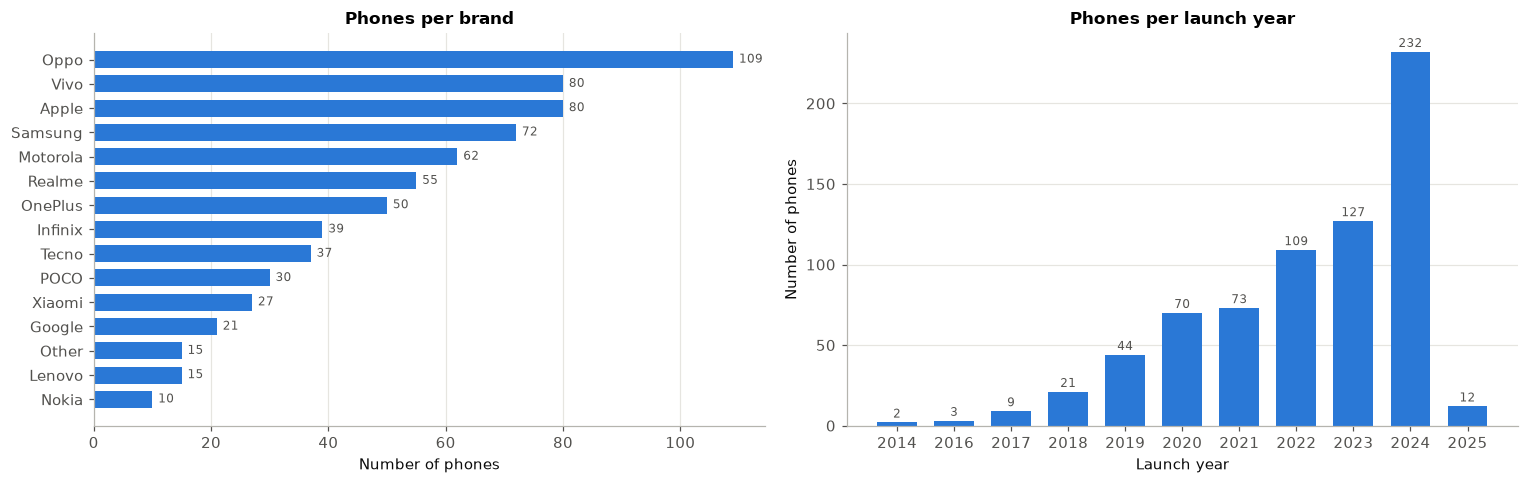

Phones from 2022–2024: 468 of 702 (67%); before 2019: 35


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
brand_counts = df["brand"].value_counts().sort_values()
axes[0].barh(brand_counts.index, brand_counts.values, color=BLUE, height=0.7)
for y, v in enumerate(brand_counts.values):
    axes[0].text(v + 1, y, str(v), va="center", fontsize=8, color=MUTED)
axes[0].set(title="Phones per brand", xlabel="Number of phones")
axes[0].grid(axis="y", visible=False)

year_counts = df["year"].value_counts().sort_index()
axes[1].bar(year_counts.index.astype(str), year_counts.values, color=BLUE, width=0.7)
for x, v in enumerate(year_counts.values):
    axes[1].text(x, v + 3, str(v), ha="center", fontsize=8, color=MUTED)
axes[1].set(title="Phones per launch year", xlabel="Launch year", ylabel="Number of phones")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("../results/fig02_counts.png")
plt.show()

print(f"Phones from 2022–2024: {df['year'].between(2022, 2024).sum()} of {len(df)} "
      f"({df['year'].between(2022, 2024).mean():.0%}); before 2019: {(df['year'] < 2019).sum()}")

**Takeaway:** the data is unbalanced. Oppo (109), Apple and Vivo (80 each) dominate, while Nokia, Lenovo and "Other" have only 10–15 phones, so their brand premiums will be the least certain. Most phones are recent: two-thirds were launched in 2022–2024 (232 in 2024 alone), and only 35 before 2019, so the model mainly describes the recent market.

## Summary of the exploration
| expected finding | result |
|---|---|
| storage and RAM correlate most with log price (~0.6, ~0.5) | **confirmed**: 0.60 and 0.52 |
| battery correlates almost zero | **rejected at first sight** (−0.26), but this is caused by Apple. Without Apple it is −0.04, so **confirmed after removing the confounder** |
| camera MP correlates almost zero | **mostly confirmed**: main 0.13, front 0.21 (weak) |

The 7 web-lookup phones change no correlation by more than 0.011, so the exploration does not depend on them.

What this means for modelling:
1. Model **log price** (symmetric target, multiplicative effects).
2. Use **log2 RAM and log2 storage**, but expect their separate coefficients to be unstable because they are correlated (0.69).
3. Include **brand** and **chip family**, because both are strongly related to price and brand confounds single-spec comparisons.
4. Treat small groups (Nokia, Lenovo, Other, the `kirin` and `other` chips) with caution.